## __New York City Taxi Trip Duration__

Kaggle is challenging you to build a model that predicts the total ride duration of taxi trips in New York City.

__Data fields__  
_id_ - a unique identifier for each trip  
_vendor_id_ - a code indicating the provider associated with the trip record  
_pickup_datetime_ - date and time when the meter was engaged  
_dropoff_datetime_ - date and time when the meter was disengaged  
_passenger_count_ - the number of passengers in the vehicle (driver entered value)  
_pickup_longitude_ - the longitude where the meter was engaged   
_pickup_latitude_ - the latitude where the meter was engaged   
_dropoff_longitude_ - the longitude where the meter was disengaged  
_dropoff_latitude_ - the latitude where the meter was disengaged  
_store_and_fwd_flag_ - This flag indicates whether the trip record was held in vehicle memory before sending to the vendor because the vehicle did not have a connection to the server - Y=store and forward; N=not a store and forward trip   
_trip_duration_ - duration of the trip in seconds

#### This notebook is specially for analysis only

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
data = pd.read_csv("data/train.csv")
data.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


- ___Check Null or Duplicated instances___ 

No null or duplicated instances

In [33]:
data.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [34]:
data.duplicated().sum()

np.int64(0)

- ___Get Info___

In [35]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 122.4 MB


In [57]:
df = data.copy()

### Remove Outliers

- ___Trip Duration___    
5% of the instances are outliers - thats approx 75k instances   
few instances go way to high in value 

_Lets remove all the outliers for now and train the model, if we see bad performance then we will add some outliers back into the data_

In [79]:
data.describe()['trip_duration'].astype(int)

count    1458644
mean         959
std         5237
min            1
25%          397
50%          662
75%         1075
max      3526282
Name: trip_duration, dtype: int64

In [80]:
## Check the 10 largest in hours
data['trip_duration'].nlargest(10) / (60*60)

978383     979.522778
924150     618.781111
680594     569.327222
355003     538.815556
1234291     23.997778
295382      23.997500
73816       23.997222
59891       23.996389
1360439     23.995833
753765      23.994167
Name: trip_duration, dtype: float64

In [44]:
##Get outliers
Q1 = df['trip_duration'].quantile(0.25)
Q2 = df['trip_duration'].quantile(0.75)

IQR = Q2 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q2 + 1.5*IQR

print("lower_bound: ", lower_bound)
print("upper_bound: ", upper_bound)

lower_bound:  -620.0
upper_bound:  2092.0


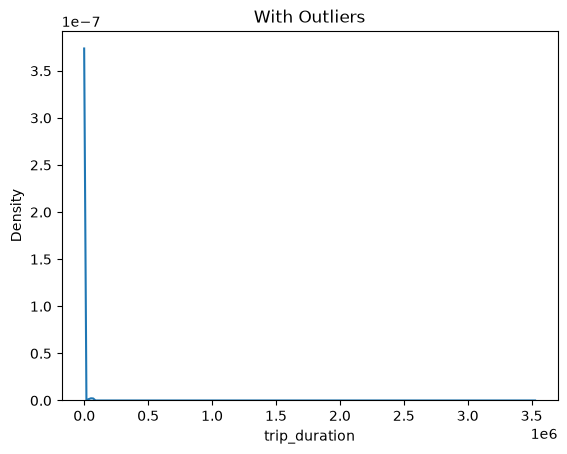

In [45]:
sns.kdeplot(df['trip_duration'])
plt.title("With Outliers")
plt.show()

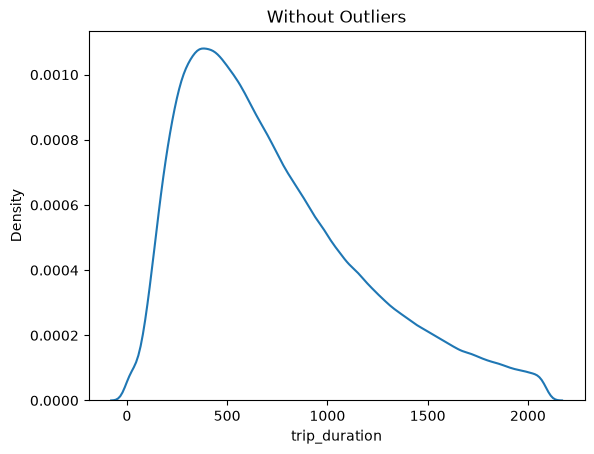

In [46]:
sns.kdeplot(df[df['trip_duration']<upper_bound]['trip_duration'])
plt.title("Without Outliers")
plt.show()

### Time Series Analysis for Avg. Trip Duration

In [47]:
## Separate Date and Time from 'pickup_datetime'
df['pickup_date'] = pd.to_datetime(data['pickup_datetime']).dt.date
df['pickup_time'] = pd.to_datetime(data['pickup_datetime']).dt.time
df.drop(columns=['pickup_datetime'], inplace=True)
df.head()

,id,vendor_id,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_date,pickup_time
0,id2875421,2,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,2016-03-14,17:24:55
1,id2377394,1,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,2016-06-12,00:43:35
2,id3858529,2,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,2016-01-19,11:35:24
3,id3504673,2,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,2016-04-06,19:32:31
4,id2181028,2,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,2016-03-26,13:30:55


In [48]:
print("Range of dates and time - \n")
print("Start Date: ", df['pickup_date'].min())
print("Last Date: ", df['pickup_date'].max())

print("Min time: ", df['pickup_time'].min())
print("Max time: ", df['pickup_time'].max())

Range of dates and time - 

Start Date:  2016-01-01
Last Date:  2016-06-30
Min time:  00:00:00
Max time:  23:59:59


In [49]:
## Calculate Avg Time Duration for each day in year
avg_duration_by_day = pd.DataFrame(df.groupby('pickup_date')['trip_duration'].mean().round(decimals=0))
avg_duration_by_day.reset_index(inplace=True)
avg_duration_by_day.rename(columns={'trip_duration':'avg_trip_duration'}, inplace=True)
avg_duration_by_day.head()

,pickup_date,avg_trip_duration
0,2016-01-01,921.0
1,2016-01-02,840.0
2,2016-01-03,925.0
3,2016-01-04,851.0
4,2016-01-05,1455.0


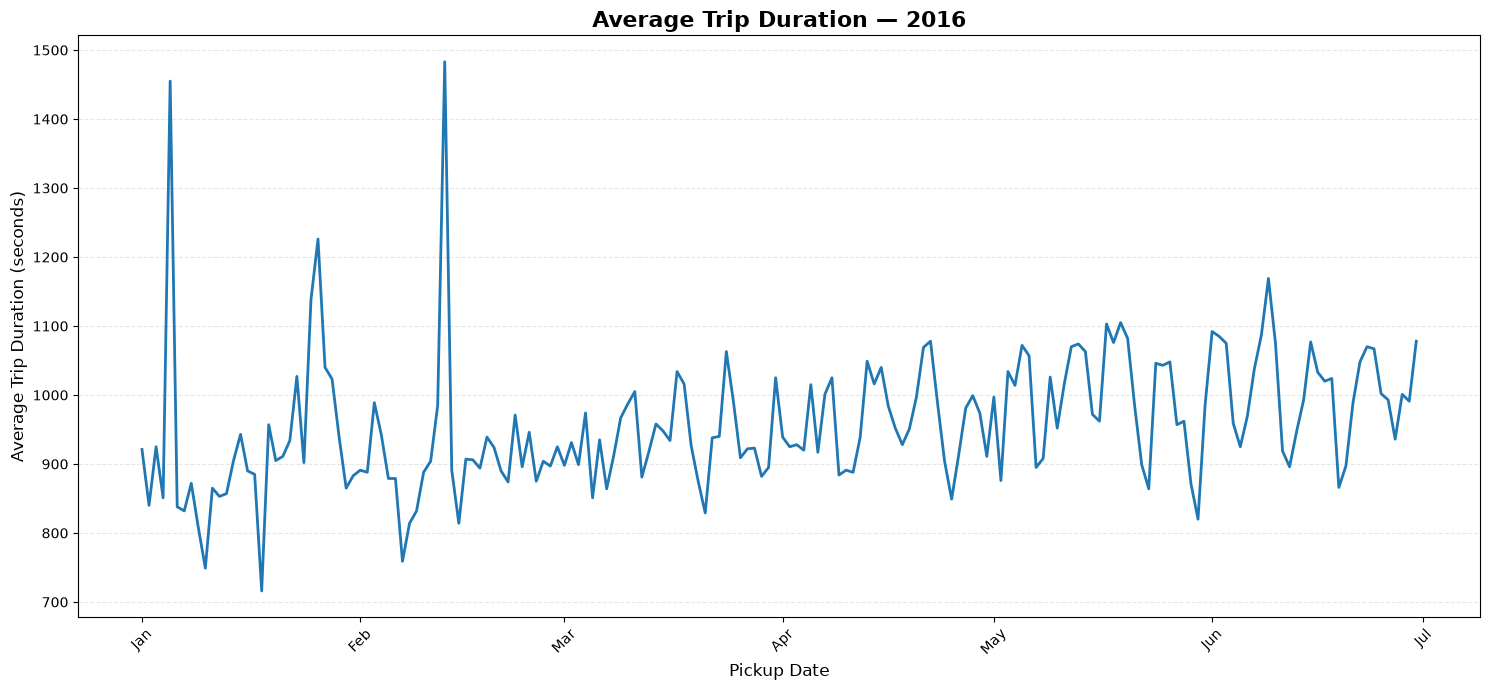

In [50]:
import matplotlib.dates as mdates

plt.figure(figsize=(15, 7))

sns.lineplot(
    data=avg_duration_by_day,
    x='pickup_date',
    y='avg_trip_duration',
    linewidth=2,
)

plt.xlabel('Pickup Date', fontsize=12)
plt.ylabel('Average Trip Duration (seconds)', fontsize=12)
plt.title('Average Trip Duration — 2016', fontsize=16, fontweight='bold')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))

plt.tight_layout()
plt.show()

In [51]:
## Get Day of Week 
df['Weekday'] = pd.to_datetime(df['pickup_date']).dt.day_name()

In [52]:
## Calculate Avg time of day for each weekday
avg_duration_by_weekday = pd.DataFrame(df.groupby('Weekday')['trip_duration'].mean().round(0))
avg_duration_by_weekday.reset_index(inplace=True)
avg_duration_by_weekday.rename(columns={'trip_duration': 'avg_trip_duration'}, inplace=True)
avg_duration_by_weekday

,Weekday,avg_trip_duration
0,Friday,990.0
1,Monday,898.0
2,Saturday,948.0
3,Sunday,902.0
4,Thursday,1007.0
5,Tuesday,983.0
6,Wednesday,975.0


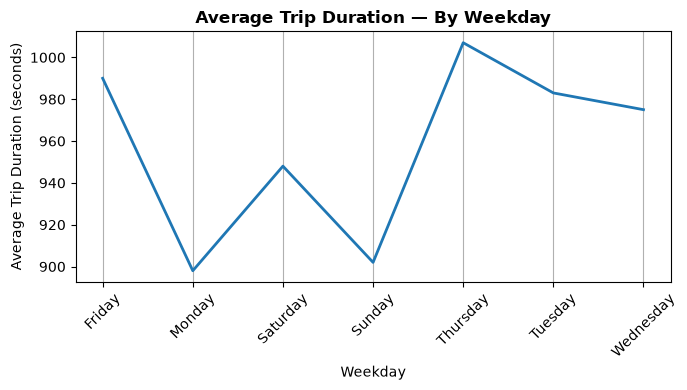

In [53]:
plt.figure(figsize=(7,4))

ax = sns.lineplot(
    data=avg_duration_by_weekday,
    x='Weekday',
    y='avg_trip_duration',
    linewidth=2,
)


plt.xlabel('Weekday', fontsize=10)
plt.ylabel('Average Trip Duration (seconds)', fontsize=10)
plt.title('Average Trip Duration — By Weekday', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()

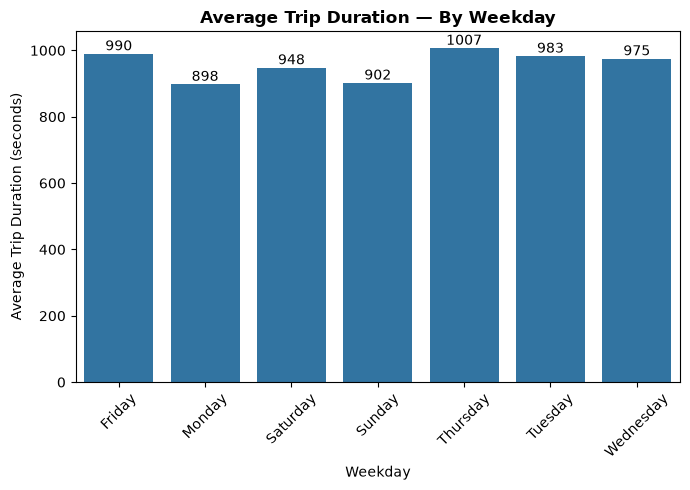

In [54]:
plt.figure(figsize=(7,5))

ax = sns.barplot(
    data=avg_duration_by_weekday,
    x='Weekday',
    y='avg_trip_duration',
    linewidth=2,
)

ax.bar_label(ax.containers[0], padding=0)
plt.xlabel('Weekday', fontsize=10)
plt.ylabel('Average Trip Duration (seconds)', fontsize=10)
plt.title('Average Trip Duration — By Weekday', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### How Trip Duration Depends on `Passenger_count`

In [58]:
df['passenger_count'].value_counts().sort_values(ascending=False)

passenger_count
1    1033540
2     210318
5      78088
3      59896
6      48333
4      28404
0         60
7          3
9          1
8          1
Name: count, dtype: int64

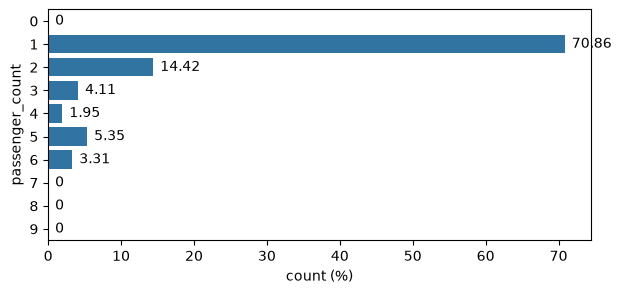

In [78]:
distribution = data['passenger_count'].value_counts()/len(data) * 100
plt.figure(figsize=(7,3))
ax = sns.barplot(distribution.round(2), orient='h')
ax.bar_label(ax.containers[0], padding=5)
plt.xlabel("count (%)")
plt.show()

In [60]:
avg_duration_by_passenger_count = pd.DataFrame(df.groupby('passenger_count')['trip_duration'].mean().round(0))
avg_duration_by_passenger_count.reset_index(inplace=True)
avg_duration_by_passenger_count

,passenger_count,trip_duration
0,0,1718.0
1,1,930.0
2,2,1005.0
3,3,1028.0
4,4,1054.0
5,5,1070.0
6,6,1061.0
7,7,20.0
8,8,104.0
9,9,560.0


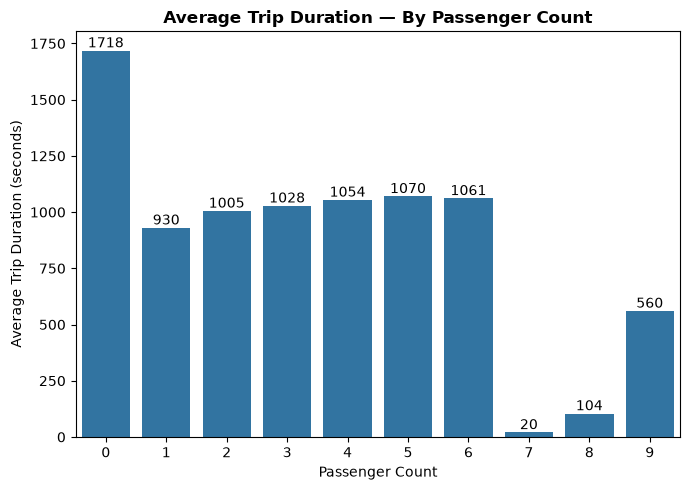

In [61]:
plt.figure(figsize=(7,5))

ax = sns.barplot(
    data=avg_duration_by_passenger_count,
    x='passenger_count',
    y='trip_duration',
    linewidth=2,
)

ax.bar_label(ax.containers[0], padding=0)

plt.xlabel('Passenger Count', fontsize=10)
plt.ylabel('Average Trip Duration (seconds)', fontsize=10)
plt.title('Average Trip Duration — By Passenger Count', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [62]:
median_duration_by_passenger_count = pd.DataFrame(df.groupby('passenger_count')['trip_duration'].median().round(0))
median_duration_by_passenger_count.reset_index(inplace=True)
median_duration_by_passenger_count

,passenger_count,trip_duration
0,0,20.0
1,1,654.0
2,2,689.0
3,3,688.0
4,4,698.0
5,5,670.0
6,6,662.0
7,7,19.0
8,8,104.0
9,9,560.0


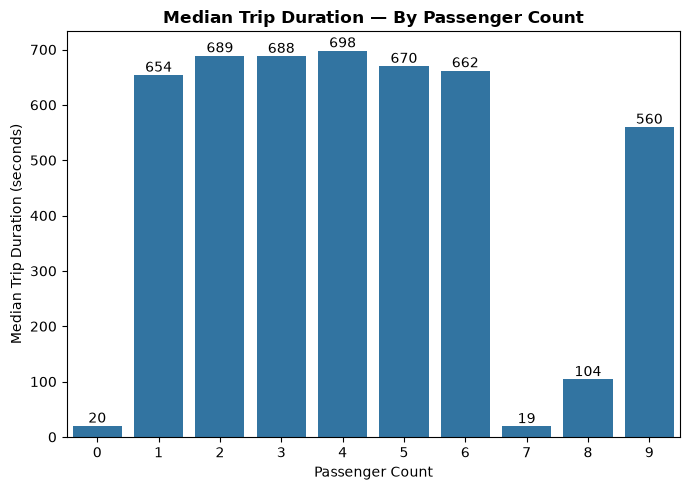

In [63]:
plt.figure(figsize=(7,5))

ax = sns.barplot(
    data=median_duration_by_passenger_count,
    x='passenger_count',
    y='trip_duration',
    linewidth=2,
)

ax.bar_label(ax.containers[0], padding=0)

plt.xlabel('Passenger Count', fontsize=10)
plt.ylabel('Median Trip Duration (seconds)', fontsize=10)
plt.title('Median Trip Duration — By Passenger Count', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Vendor Id Distribution

In [64]:
vendor_id_dist = df['vendor_id'].value_counts(normalize=True)*100
vendor_id_dist.sort_index(inplace=True)
vendor_id_dist

vendor_id
1    46.504973
2    53.495027
Name: proportion, dtype: float64

In [65]:
avg_duration_by_vendor = df.groupby('vendor_id')['trip_duration'].mean().round()
avg_duration_by_vendor

vendor_id
1     845.0
2    1059.0
Name: trip_duration, dtype: float64

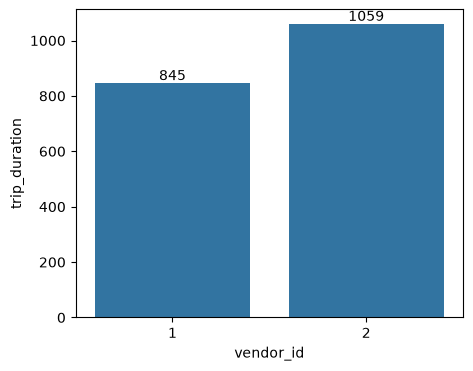

In [66]:
plt.figure(figsize=(5,4))
ax = sns.barplot(avg_duration_by_vendor)
ax.bar_label(ax.containers[0], padding=0)
plt.show()

### Store And Fwd Flag

In [67]:
flag_dist = df['store_and_fwd_flag'].value_counts(normalize=True)*100
flag_dist

store_and_fwd_flag
N    99.44846
Y     0.55154
Name: proportion, dtype: float64

In [68]:
avg_duration_by_flag = df.groupby('store_and_fwd_flag')['trip_duration'].mean().round(0)
avg_duration_by_flag

store_and_fwd_flag
N     959.0
Y    1081.0
Name: trip_duration, dtype: float64